# TD6 — Exercice 1 : Variogramme 1D du prix de l'or (GoldPrice)

**Traitement statistique, géostatistique et approche systèmes — ENSG 2A (S7)**

La variable **`GoldPrice`** est le **prix de l'or en dollars par once ($/once)**. C'est une donnée **1D** : 4 174 valeurs ordonnées le long de l'axe `MD` (*Measured Depth* = la **profondeur mesurée** le long du forage, en mètres).

**Objectif** : étudier sa distribution (histogramme, courbe cumulative) puis calculer et ajuster un **variogramme 1D**.

## Aperçu des fonctions utilisées

Petit récapitulatif de ce que fait chaque fonction clé de ce notebook :

| Fonction | Rôle |
|---|---|
| `pd.read_csv(...)` | Charge les données du prix de l'or depuis le fichier CSV |
| `gl.defineDefaultSpace(RN, 1)` | Définit l'espace de travail en **1D** (le long de l'axe `MD`) |
| `gutils.creer_db_gstlearn(...)` | Crée la base de données gstlearn (`Db`) à partir du tableau pandas |
| `gl.VarioParam.createOmniDirection(...)` | Définit les paramètres du variogramme (nb de lags, distance de lag) |
| `gl.Vario.computeFromDb(...)` | Calcule le variogramme **expérimental** |
| `gl.Model().fit(...)` | Ajuste automatiquement un **modèle théorique** (sphérique, nugget…) |
| `gutils.afficher_variogramme(...)` | Trace le variogramme expérimental **+ le modèle** ajusté |
| `widgets` / `interactive_output` | Permet le **réglage manuel interactif** du modèle (nugget, portée) |


## 1. Chargement des données

On charge le fichier `prix_or_1D.csv` contenant les 4 174 valeurs du prix de l'or.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gstlearn as gl
import gstlearn.plot as gp
import ipywidgets as widgets
from ipywidgets import interactive_output

# Ajout du chemin d'importation pour le module geostat_utils 
sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

# ---- Chargement des données du GoldPrice 1D ----
data_prix_or = pd.read_csv('../../../data/prix_or_1D.csv')
display(data_prix_or.head(3))

# ---- Dossier de sauvegarde des figures ----
DOSSIER_SORTIE = "../../../outputs/gold"
os.makedirs(DOSSIER_SORTIE, exist_ok=True)

,WELLNAME,X,Y,Z,MD,GoldPrice
0,GoldPrice,0,0,6000,0,397.5
1,GoldPrice,0,0,5997,3,395.0
2,GoldPrice,0,0,5996,4,403.5


## 2. Série temporelle du prix de l'or

Avant d'étudier la distribution statistique, on visualise les données telles qu'elles ont été mesurées : le `GoldPrice` le long de l'axe `MD`. Comme 1 m (MD) = 1 jour, et que la première mesure correspond au 01/01/1982, on peut convertir `MD` en une vraie date pour obtenir une série temporelle interprétable.

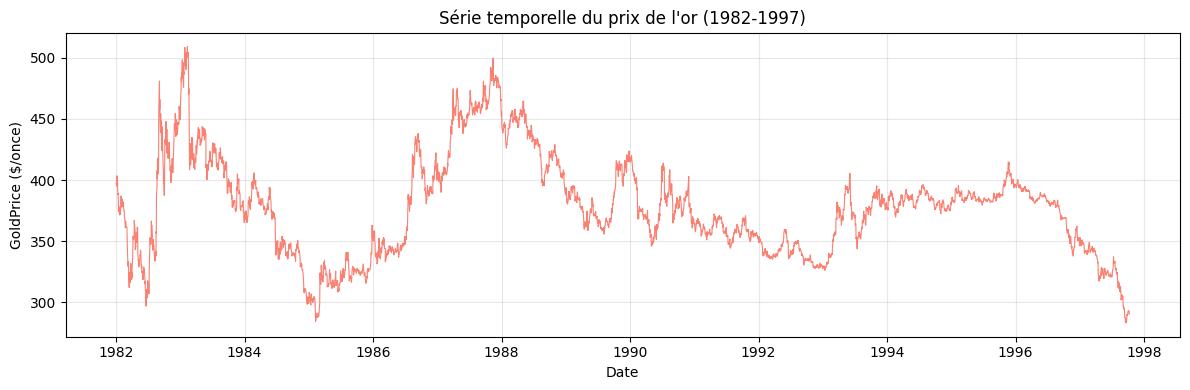

In [2]:
#---- Série temporelle du prix de l'or  ----
date_debut = pd.Timestamp("1982-01-01")
data_prix_or["Date"] = date_debut + pd.to_timedelta(data_prix_or["MD"], unit="D")
plt.figure(figsize=(12, 4))
plt.plot(data_prix_or["Date"], data_prix_or["GoldPrice"], color='salmon', linewidth=0.8)
plt.title("Série temporelle du prix de l'or (1982-1997)")
plt.xlabel("Date")
plt.ylabel("GoldPrice ($/once)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DOSSIER_SORTIE}/ex1_serie_temporelle.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Histogramme et courbe cumulative

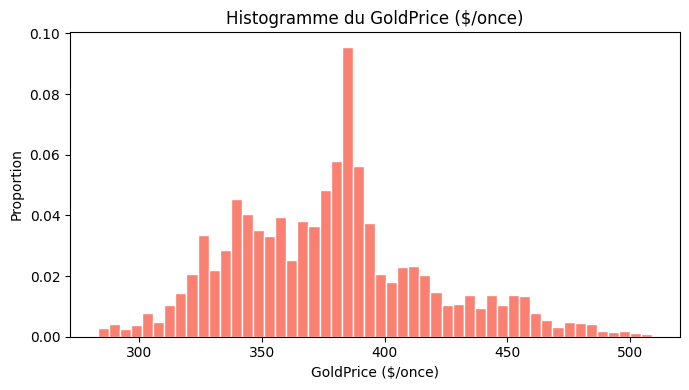

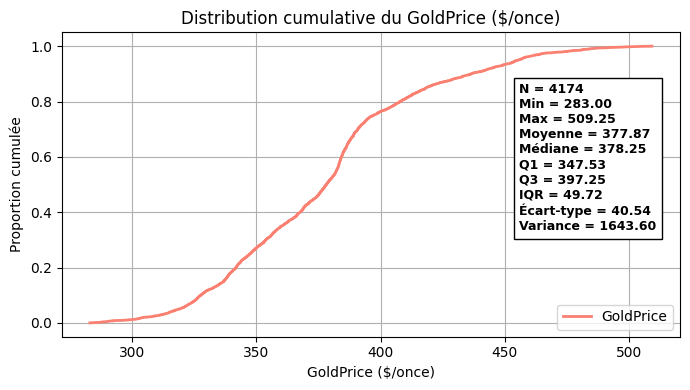

In [3]:
#----calcul histogramme du GoldPrice----

gp_valeurs = data_prix_or['GoldPrice']
plt.figure (figsize=(7, 4))
plt.hist(gp_valeurs, bins=50, weights = np.ones(len(gp_valeurs))/len(gp_valeurs),
          color ='salmon' , edgecolor='white')
plt.title("Histogramme du GoldPrice ($/once)")
plt.xlabel("GoldPrice ($/once)")
plt.ylabel("Proportion")
plt.tight_layout()
plt.savefig(f"{DOSSIER_SORTIE}/ex1_histogramme.png", dpi=150, bbox_inches="tight")
plt.show()

#----------Statistques du GoldPrice--------

nombre_mesures=len(gp_valeurs)
min_value = np.min(gp_valeurs)
max_value = np.max(gp_valeurs)
moyenne_gp = np.mean(gp_valeurs)
mediane_gp = np.median(gp_valeurs)
premier_quartile = np.percentile(gp_valeurs,25)
troisieme_quartile = np.percentile(gp_valeurs,75)
IQR= troisieme_quartile-premier_quartile
ecart_type_gp = np.std(gp_valeurs, ddof=1)
variance_gp = np.var(gp_valeurs, ddof=1)
gold_trie = np.sort(gp_valeurs)
gp_cumulative = np.arange (1,len(gold_trie)+1)/len(gold_trie)

#----------Distribution cumulative(GoldPrice)-------- 

plt.figure(figsize=(7,4))
plt.plot(gold_trie, gp_cumulative, color='salmon' ,linewidth=2 , label='GoldPrice')
plt.title("Distribution cumulative du GoldPrice ($/once)")
plt.xlabel("GoldPrice ($/once)")
plt.ylabel("Proportion cumulée")
plt.legend(loc='lower right')

# ---- Statistiques sur le graphe ----
text_stats = (
    f"N = {nombre_mesures}\n"
    f"Min = {min_value:.2f}\n"
    f"Max = {max_value:.2f}\n"
    f"Moyenne = {moyenne_gp:.2f}\n"
    f"Médiane = {mediane_gp:.2f}\n"
    f"Q1 = {premier_quartile:.2f}\n"
    f"Q3 = {troisieme_quartile:.2f}\n"
    f"IQR = {IQR:.2f}\n"
    f"Écart-type = {ecart_type_gp:.2f}\n"
    f"Variance = {variance_gp:.2f}"
)
plt.text(0.74, 0.35,
    text_stats,
    transform=plt.gca().transAxes,
    fontsize=9,
    fontweight='bold',
    bbox=dict(facecolor='white', edgecolor='black')
)
plt.grid()
plt.tight_layout()
plt.savefig(f"{DOSSIER_SORTIE}/ex1_cumulative.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Création de la base de données gstlearn (1D)

In [4]:
#------ Définir l'espace 1D -----
gl.defineDefaultSpace(gl.ESpaceType.RN, 1)
# ---- Création de la base de données gstlearn en espace 1D (fonction factorisée) ----
db_prix_or = gutils.creer_db_gstlearn(
    data_prix_or,
    variables=["MD", "GoldPrice"],
    noms_locators=["x1", "z1"]
)
print(db_prix_or)


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 1
Number of Columns            = 3
Total number of samples      = 4174

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = MD - Locator = x1
Column = 2 - Name = GoldPrice - Locator = z1



## 5. Variogramme expérimental en 1D

### 5.1 Définir les paramètres du variogramme en 1D

In [5]:
#---- Définition des paramètres du variogramme en 1D ----
# Mêmes paramètres que SKUA (Vertical Variogram)
etendue_md = data_prix_or["MD"].max()-data_prix_or["MD"].min()
nombre_classe = 15
taille_classe = 192 
print (f"Étendue du puits selon MD : {etendue_md:.0f}m")
print (f"Nombre de classe (nlag): {nombre_classe}")
print (f"Taille d'une classe (dlag): {taille_classe}m")

Étendue du puits selon MD : 5760m
Nombre de classe (nlag): 15
Taille d'une classe (dlag): 192m


### 5.2 Calcul et affichage du variogramme

In [6]:
#---- Calcul du variogramme expérimental en 1D ----
params_vario_prix_or = gl.VarioParam.createOmniDirection(
    nlag=nombre_classe,
    dlag=taille_classe,
    toldis=0.5
)

vario_prix_or = gl.Vario.computeFromDb(
    varioparam=params_vario_prix_or,
    db=db_prix_or
)
print(vario_prix_or)


Variogram characteristics
Number of variable(s)       = 1
Number of direction(s)      = 1
Space dimension             = 1
Variable(s)                 = [GoldPrice]

Variance-Covariance Matrix   1643.203

Direction #1
------------
Number of lags              = 15
Direction coefficients      =       1.000
Tolerance on direction      =      90.000 (degrees)
Calculation lag             =     192.000
Tolerance on distance       =      50.000 (Percent of the lag value)

For variable 1
       Rank     Npairs   Distance      Value
          0 283866.000     47.872    220.816
          1 561571.000    190.774    682.930
          2 542610.000    382.848   1286.355
          3 523275.000    574.982   1877.966
          4 503309.000    767.040   2286.729
          5 483432.000    958.910   2357.801
          6 464469.000   1150.741   2196.636
          7 445214.000   1342.660   1888.693
          8 426415.000   1534.702   1664.892
          9 406941.000   1726.852   1587.051
         10 387185.0

Variance GoldPrice = 1643.60


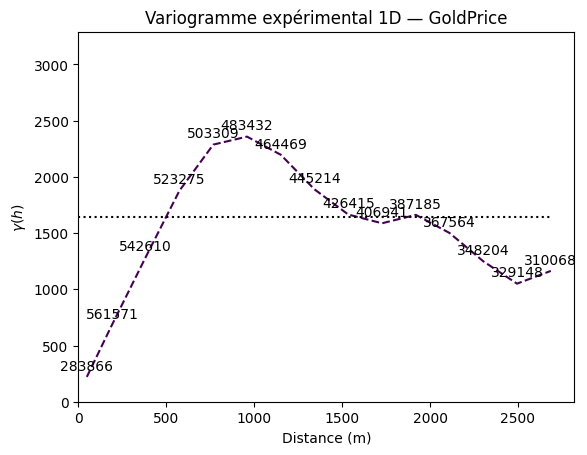

In [7]:
#---- Affichage du variogramme expérimental en 1D ----
variance_prix_or = np.var(data_prix_or['GoldPrice'], ddof=1)
print(f"Variance GoldPrice = {variance_prix_or:.2f}")
ax = gp.varmod(vario_prix_or, showPairs=True)
ax.set_ylim(0, variance_prix_or * 2)
plt.xlabel("Distance (m)")
plt.ylabel(r"$\gamma(h)$")
plt.title("Variogramme expérimental 1D — GoldPrice")
plt.savefig(f"{DOSSIER_SORTIE}/ex1_variogramme_exp.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Ajustement automatique du modèle

### 6.1 Modèle Sphérique sans nugget

Variance GoldPrice = 1643.60


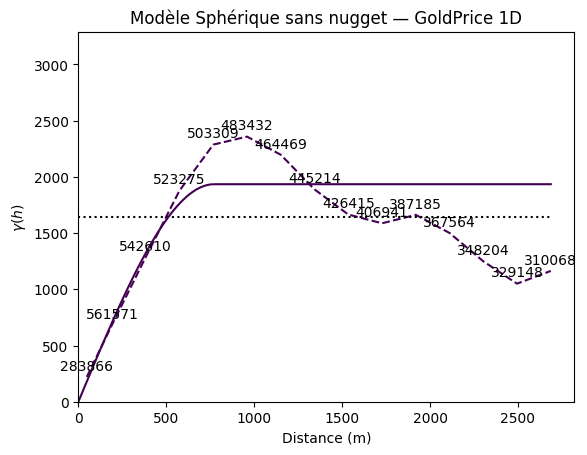


Model characteristics
Space dimension              = 1
Number of variable(s)        = 1
Number of basic structure(s) = 1
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Spherical
- Sill         =    1934.550
- Range        =     771.168
Total Sill     =    1934.550
Known Mean(s)      0.000



In [8]:
#---- Ajustement automatique - Modèle Sphérique sans nugget ----
# Affichage factorisé via gutils.afficher_variogramme 
variance_prix_or = np.var(data_prix_or['GoldPrice'], ddof=1)
print(f"Variance GoldPrice = {variance_prix_or:.2f}")

model_sph_prix_or = gl.Model()
err = model_sph_prix_or.fit(vario_prix_or, types=[gl.ECov.SPHERICAL])
gutils.afficher_variogramme(
    vario_prix_or, model_sph_prix_or,
    "Modèle Sphérique sans nugget — GoldPrice 1D",
    variance_prix_or, unite="m",
    chemin_fichier=f"{DOSSIER_SORTIE}/ex1_modele_spherique.png"
)

### 6.2 Modèle Sphérique avec Nugget

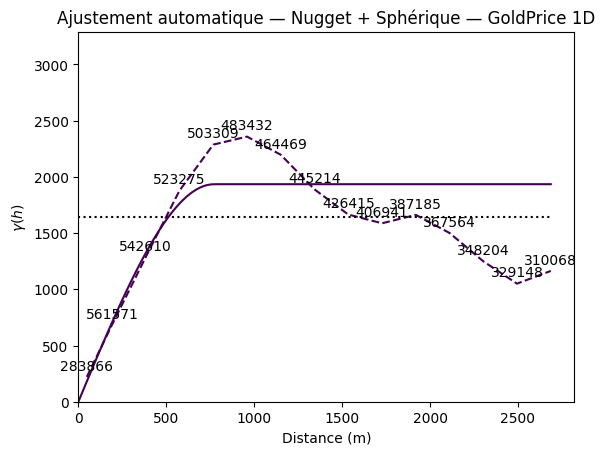


Model characteristics
Space dimension              = 1
Number of variable(s)        = 1
Number of basic structure(s) = 1
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Spherical
- Sill         =    1934.562
- Range        =     771.186
Total Sill     =    1934.562
Known Mean(s)      0.000



In [9]:
#---- Ajustement automatique - Nugget + Sphérique ----
model_nug_sph_prix_or = gl.Model()
err = model_nug_sph_prix_or.fit(vario_prix_or, types=[gl.ECov.NUGGET, gl.ECov.SPHERICAL])
gutils.afficher_variogramme(
    vario_prix_or, model_nug_sph_prix_or,
    "Ajustement automatique — Nugget + Sphérique — GoldPrice 1D",
    variance_prix_or, unite="m",
    chemin_fichier=f"{DOSSIER_SORTIE}/ex1_modele_nugget_spherique.png"
)

### 6.3 Ajustement manuel interactif

In [10]:
calage_gold = gutils.creer_widget_calage_variogramme(
    vario_prix_or, variance_prix_or,
    valeurs_defaut={
        'Spherique':   (0.0, 1440.0),
        'Exponentiel': (0.0, 2000.0),
        'Gaussien':    (0.0, 1200.0),
    },
    facteur_correction=variance_prix_or,
    unite="m",
    portee_min=100.0,
    portee_max=3000.0,
    chemin_sortie=DOSSIER_SORTIE,
)

In [11]:
model_final_gold = calage_gold.model
print(model_final_gold)


Model characteristics
Space dimension              = 1
Number of variable(s)        = 1
Number of basic structure(s) = 2
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Nugget Effect
- Sill         =       0.000
Spherical
- Sill         =    1643.597
- Range        =    1440.000
Total Sill     =    1643.597
Known Mean(s)      0.000

